# METIS sweep config

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These tutorials use a CPU and the full original SIRDS bank. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `7a0813987944`](https://github.com/OJWatson/metis/tree/7a081398794492c82d92812b5801900f62f8639a).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Short uv setup cell shared by downloadable notebooks."""

import os
from pathlib import Path
import re
import shlex
import subprocess
import sys


def prepare_colab(revision):
    """Use the checkout's locked environment in Colab's active interpreter."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    if not (os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION")):
        print("Using your local METIS environment.")
        return
    # The source commit matches the results saved in this notebook.
    source = Path("/content/metis-tutorial")
    commands = f'''
set -euo pipefail
export PATH="$HOME/.local/bin:$PATH"
command -v uv >/dev/null || curl -LsSf https://astral.sh/uv/0.7.22/install.sh | sh
[ -d {source}/.git ] || git clone -q https://github.com/OJWatson/metis.git {source}
git -C {source} fetch -q origin {revision}
git -C {source} checkout -q --detach {revision}
uv sync --project {source} --python {shlex.quote(sys.executable)} --locked --inexact --no-dev --extra docs --no-editable
'''
    subprocess.run(
        ["bash", "-c", commands], check=True,
        env={**os.environ, "UV_PROJECT_ENVIRONMENT": sys.prefix, "UV_NO_MODIFY_PATH": "1"},
    )
    print("METIS is ready. If Colab reports a library-version conflict or asks for a restart, restart the session, then Run all.")


prepare_colab("7a081398794492c82d92812b5801900f62f8639a")


## Walkthrough: sweeping on SIRDS

In this walkthrough we'll set up a sweep for an MLP on the same SIRDS simulation
bank. As with training, sweeps in METIS are driven through a configuration.

### 1. Hyperparameters to sweep over

We'll vary the learning rate, warmup fraction, number of model blocks and hidden
dimension. Batch size and training duration stay fixed. The cosine schedule
uses the warmup fraction to increase the learning rate at the start of training
before gradually reducing it.

If you're starting with a small experiment budget, first compare a few
learning rates before widening the search.

### 2. Choosing a metric to optimise

We'll target `validation/rmse`, which measures error in the original SIRDS count
units. Setting `evaluation.partition=validation` keeps the test set out of the
sweep. Use the same split seed for every run.

### 3. Choosing the sampling strategy and number of runs

W&B supports `grid` searches over all combinations, `random` sampling, and
`bayes`, which uses Bayesian optimisation to choose the next configuration.
Here we'll use `bayes` and start with a budget of ten runs.

Each parameter can have a fixed list of values or a sampling distribution.
Putting the settings together gives:

```yaml
program: metis-train
project: sirds-surrogates
method: bayes
metric:
  name: validation/rmse
  goal: minimize

parameters:
  # Fixed settings
  dataset:
    value: example
  model:
    value: mlp
  split.seed:
    value: 42
  evaluation.partition:
    value: validation
  wandb.enabled:
    value: true
  wandb.project:
    value: sirds-surrogates
  training.batch_size:
    value: 64
  training.steps:
    value: 1000
  training.schedule:
    value: warmup_cosine

  # Parameters to optimise
  training.learning_rate:
    min: 0.0001
    max: 0.01
    distribution: log_uniform_values
  training.warmup_fraction:
    values: [0.0, 0.1, 0.2]
  model.model_options.num_blocks:
    values: [2, 4]
  model.model_options.hidden_dim:
    values: [32, 64, 128]

command:
  - ${env}
  - ${program}
  - ${args_no_hyphens}
```

`dataset=example` selects the SIRDS bank installed with METIS. `metis-train` is
the installed Hydra entry point; the sweep does not need a repository checkout.

Save this as `sirds-mlp-sweep.yaml` and register it with W&B:

```bash
uv run wandb sweep --project sirds-surrogates sirds-mlp-sweep.yaml
```

This returns an identifier of the form `ENTITY/PROJECT/SWEEP_ID`.

### 4. Launching sweep agents

A W&B agent launches the training runs locally or on another machine where
METIS and your data are available. Use the identifier returned above:

```bash
uv run wandb agent --count 10 ENTITY/PROJECT/SWEEP_ID
```

Each run saves its resolved configuration, model and evaluation report in its
own output directory. Review the validation results in W&B, then evaluate the
selected model on the held-out test set.

For a small local grid without W&B, the same installed workflow also supports:

```bash
uv run metis train --multirun training.learning_rate=0.001,0.0003 training.steps=1000 training.batch_size=64 training.eval_every=100 evaluation.partition=validation
```

Here is the result of running that two-rate grid for 1,000 updates per run on
the full SIRDS bank. Each run uses the same 600 training and 200 validation
settings. The test set is not used to choose the learning rate.

In [1]:
#| code-fold: true
#| code-summary: "Run the Hydra grid and read its saved validation metrics"
import json
from pathlib import Path
import subprocess
import sys
import pandas as pd
import matplotlib.pyplot as plt

sweep_directory = Path("sirds-learning-rate-sweep").resolve()
subprocess.run(
    [sys.executable, "-m", "metis.hydra_app", "--multirun",
     "training.learning_rate=0.001,0.0003", "training.steps=1000",
     "training.batch_size=64", "training.eval_every=100",
     "evaluation.partition=validation", f"hydra.sweep.dir={sweep_directory}"],
    check=True, capture_output=True, text=True,
)
results = []
for index, rate in enumerate([0.001, 0.0003]):
    saved = json.loads((sweep_directory / str(index) / "metrics.json").read_text())
    results.append({"Learning rate": rate, "Validation RMSE (people)": saved["metrics"]["rmse"]})
results = pd.DataFrame(results)
results

,Learning rate,Validation RMSE (people)
0,0.0010,41.593759
1,0.0003,46.461233


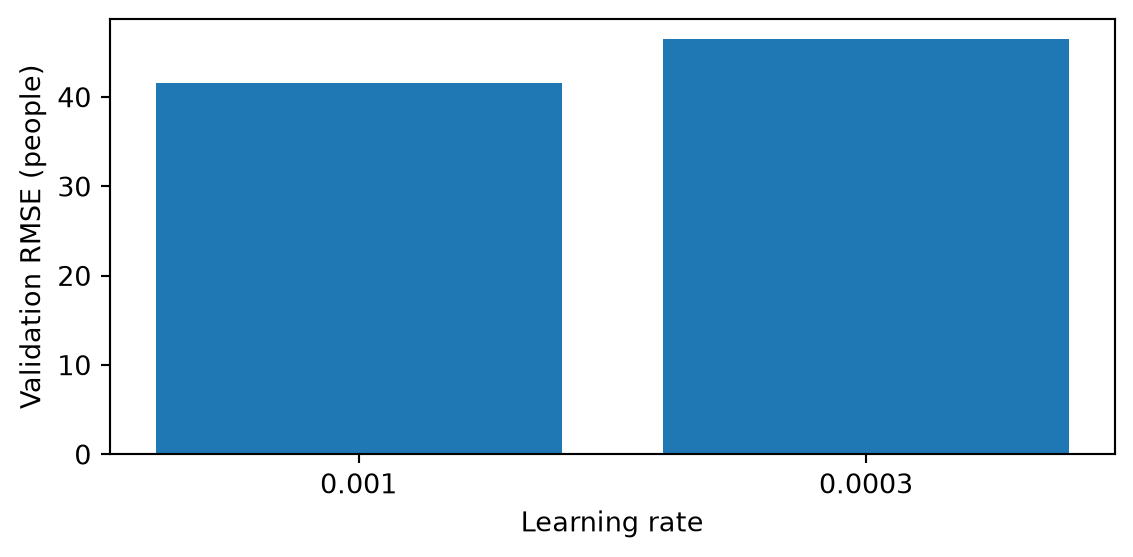

In [2]:
#| fig-cap: "MLP learning-rate grid: each model fitted to the same 600 full-bank SIRDS training settings and evaluated on 200 validation settings after 1,000 updates."
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(results["Learning rate"].astype(str), results["Validation RMSE (people)"])
ax.set(xlabel="Learning rate", ylabel="Validation RMSE (people)")
fig.tight_layout()
plt.show()

*MLP learning-rate grid: each model fitted to the same 600 full-bank SIRDS training settings and evaluated on 200 validation settings after 1,000 updates.*

This is a two-run demonstration of the sweep workflow, not an exhaustive
hyperparameter search. A W&B sweep collects the same validation metric while
choosing configurations using its search strategy.